# Sound Classification

This project compares SVM, Random Forest, and Gradient Boosting on a 12 class sound classification task and evaluates how well the best model generalizes to my own recordings collected under different conditions.

## Feature Extraction

In [26]:
import pandas as pd
import soundfile as sf
import numpy as np
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier)
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedGroupKFold
from pathlib import Path

In [2]:
def extract_features(signal):
	peak = np.max(np.abs(signal))
	rms = np.sqrt(np.mean(signal ** 2))

	rms_dbfs = float(20 * np.log10(max(rms, 1e-10)))
	crest_factor = float(20 * np.log10(peak / rms)) if rms > 1e-10 else 0.0

	rms_frames = librosa.feature.rms(
		y=signal,
        frame_length=512,
        hop_length=160,
        center=False
    )[0]

	frames_dbfs = 20 * np.log10(np.maximum(rms_frames, 1e-10))

	background_frames =  float(np.percentile(frames_dbfs, 10))

	signal_level_dbfs = np.percentile(frames_dbfs, 95)
	noise_level_dbfs = np.percentile(frames_dbfs, 10)

	approximate_snr_db = float(signal_level_dbfs - noise_level_dbfs)

	threshold_dbfs = np.max(frames_dbfs) - 20

	active_frame_fraction = float(np.mean(frames_dbfs >= threshold_dbfs))

	centroid = librosa.feature.spectral_centroid(
        y=signal, sr=16_000, n_fft=512,
        hop_length=160, center=False
    )[0]

	bandwidth = librosa.feature.spectral_bandwidth(
        y=signal, sr=16_000, n_fft=512,
        hop_length=160, center=False
    )[0]

	rolloff85 = librosa.feature.spectral_rolloff(
        y=signal, sr=16_000, n_fft=512,
        hop_length=160, roll_percent=0.85, center=False
    )[0]

	flatness = librosa.feature.spectral_flatness(
        y=signal, n_fft=512,
        hop_length=160, center=False
    )[0]

	zero_crossing_rate = librosa.feature.zero_crossing_rate(
        y=signal, frame_length=512,
        hop_length=160, center=False
    )[0]

	features = [
		rms_dbfs,
		crest_factor,
		background_frames,
		approximate_snr_db,
		active_frame_fraction,
		float(np.mean(centroid)),
        float(np.mean(bandwidth)),
        float(np.mean(rolloff85)),
        float(np.mean(flatness)),
        float(np.mean(zero_crossing_rate))
	]

	mfcc = librosa.feature.mfcc(
        y=signal,
        sr=16_000,
        n_mfcc=20,
        n_fft=512,
        hop_length=160,
        center=False
    )

	for i in range(20):
		features.append(float(np.mean(mfcc[i])))
		features.append(float(np.std(mfcc[i])))
		
	return features


In [3]:
feature_names = [
    "rms_dbfs",
    "crest_factor_db",
    "background_noise_dbfs",
    "approximate_snr_db",
    "active_frame_fraction",
    "spectral_centroid_mean",
    "spectral_bandwidth_mean",
    "spectral_rolloff85_mean",
    "spectral_flatness_mean",
    "zero_crossing_rate_mean",
]

for i in range(1, 21):
    feature_names.extend([f"mfcc_{i}_mean", f"mfcc_{i}_std"])

In [4]:
metadata = pd.read_csv("metadata.csv")

feature_rows = []
labels = []

for _, row in metadata.iterrows():
    audio, sr = sf.read(row["filename"], dtype="float32")
    feature_rows.append(extract_features(audio))
    labels.append(row["label"])

C:\Users\adela\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
feature_matrix = np.asarray(feature_rows)

metadata_cols = ["filename", "label", "split", "source_id"]

train_mask = metadata["split"] == "train"
val_mask = metadata["split"] == "val"
test_mask = metadata["split"] == "test"

train_df = pd.concat(
    [
        metadata.loc[train_mask, metadata_cols].reset_index(drop=True),
        pd.DataFrame(
            feature_matrix[train_mask.to_numpy()],
            columns=feature_names
        )
    ],
    axis=1
)

val_df = pd.concat(
    [
        metadata.loc[val_mask, metadata_cols].reset_index(drop=True),
        pd.DataFrame(
            feature_matrix[val_mask.to_numpy()],
            columns=feature_names
        )
    ],
    axis=1
)

test_df = pd.concat(
    [
        metadata.loc[test_mask, metadata_cols].reset_index(drop=True),
        pd.DataFrame(
            feature_matrix[test_mask.to_numpy()],
            columns=feature_names
        )
    ],
    axis=1
)

In [6]:
X_train = train_df[feature_names]
y_train = train_df["label"]

X_val = val_df[feature_names]
y_val = val_df["label"]

X_test = test_df[feature_names]
y_test = test_df["label"]

## Exploratory Data Anlysis

In [7]:
analyzed_features = [
    "rms_dbfs",
    "crest_factor_db",
    "background_noise_dbfs",
    "approximate_snr_db",
    "active_frame_fraction",
    "spectral_centroid_mean",
    "spectral_bandwidth_mean",
    "spectral_rolloff85_mean",
    "spectral_flatness_mean",
    "zero_crossing_rate_mean",
]

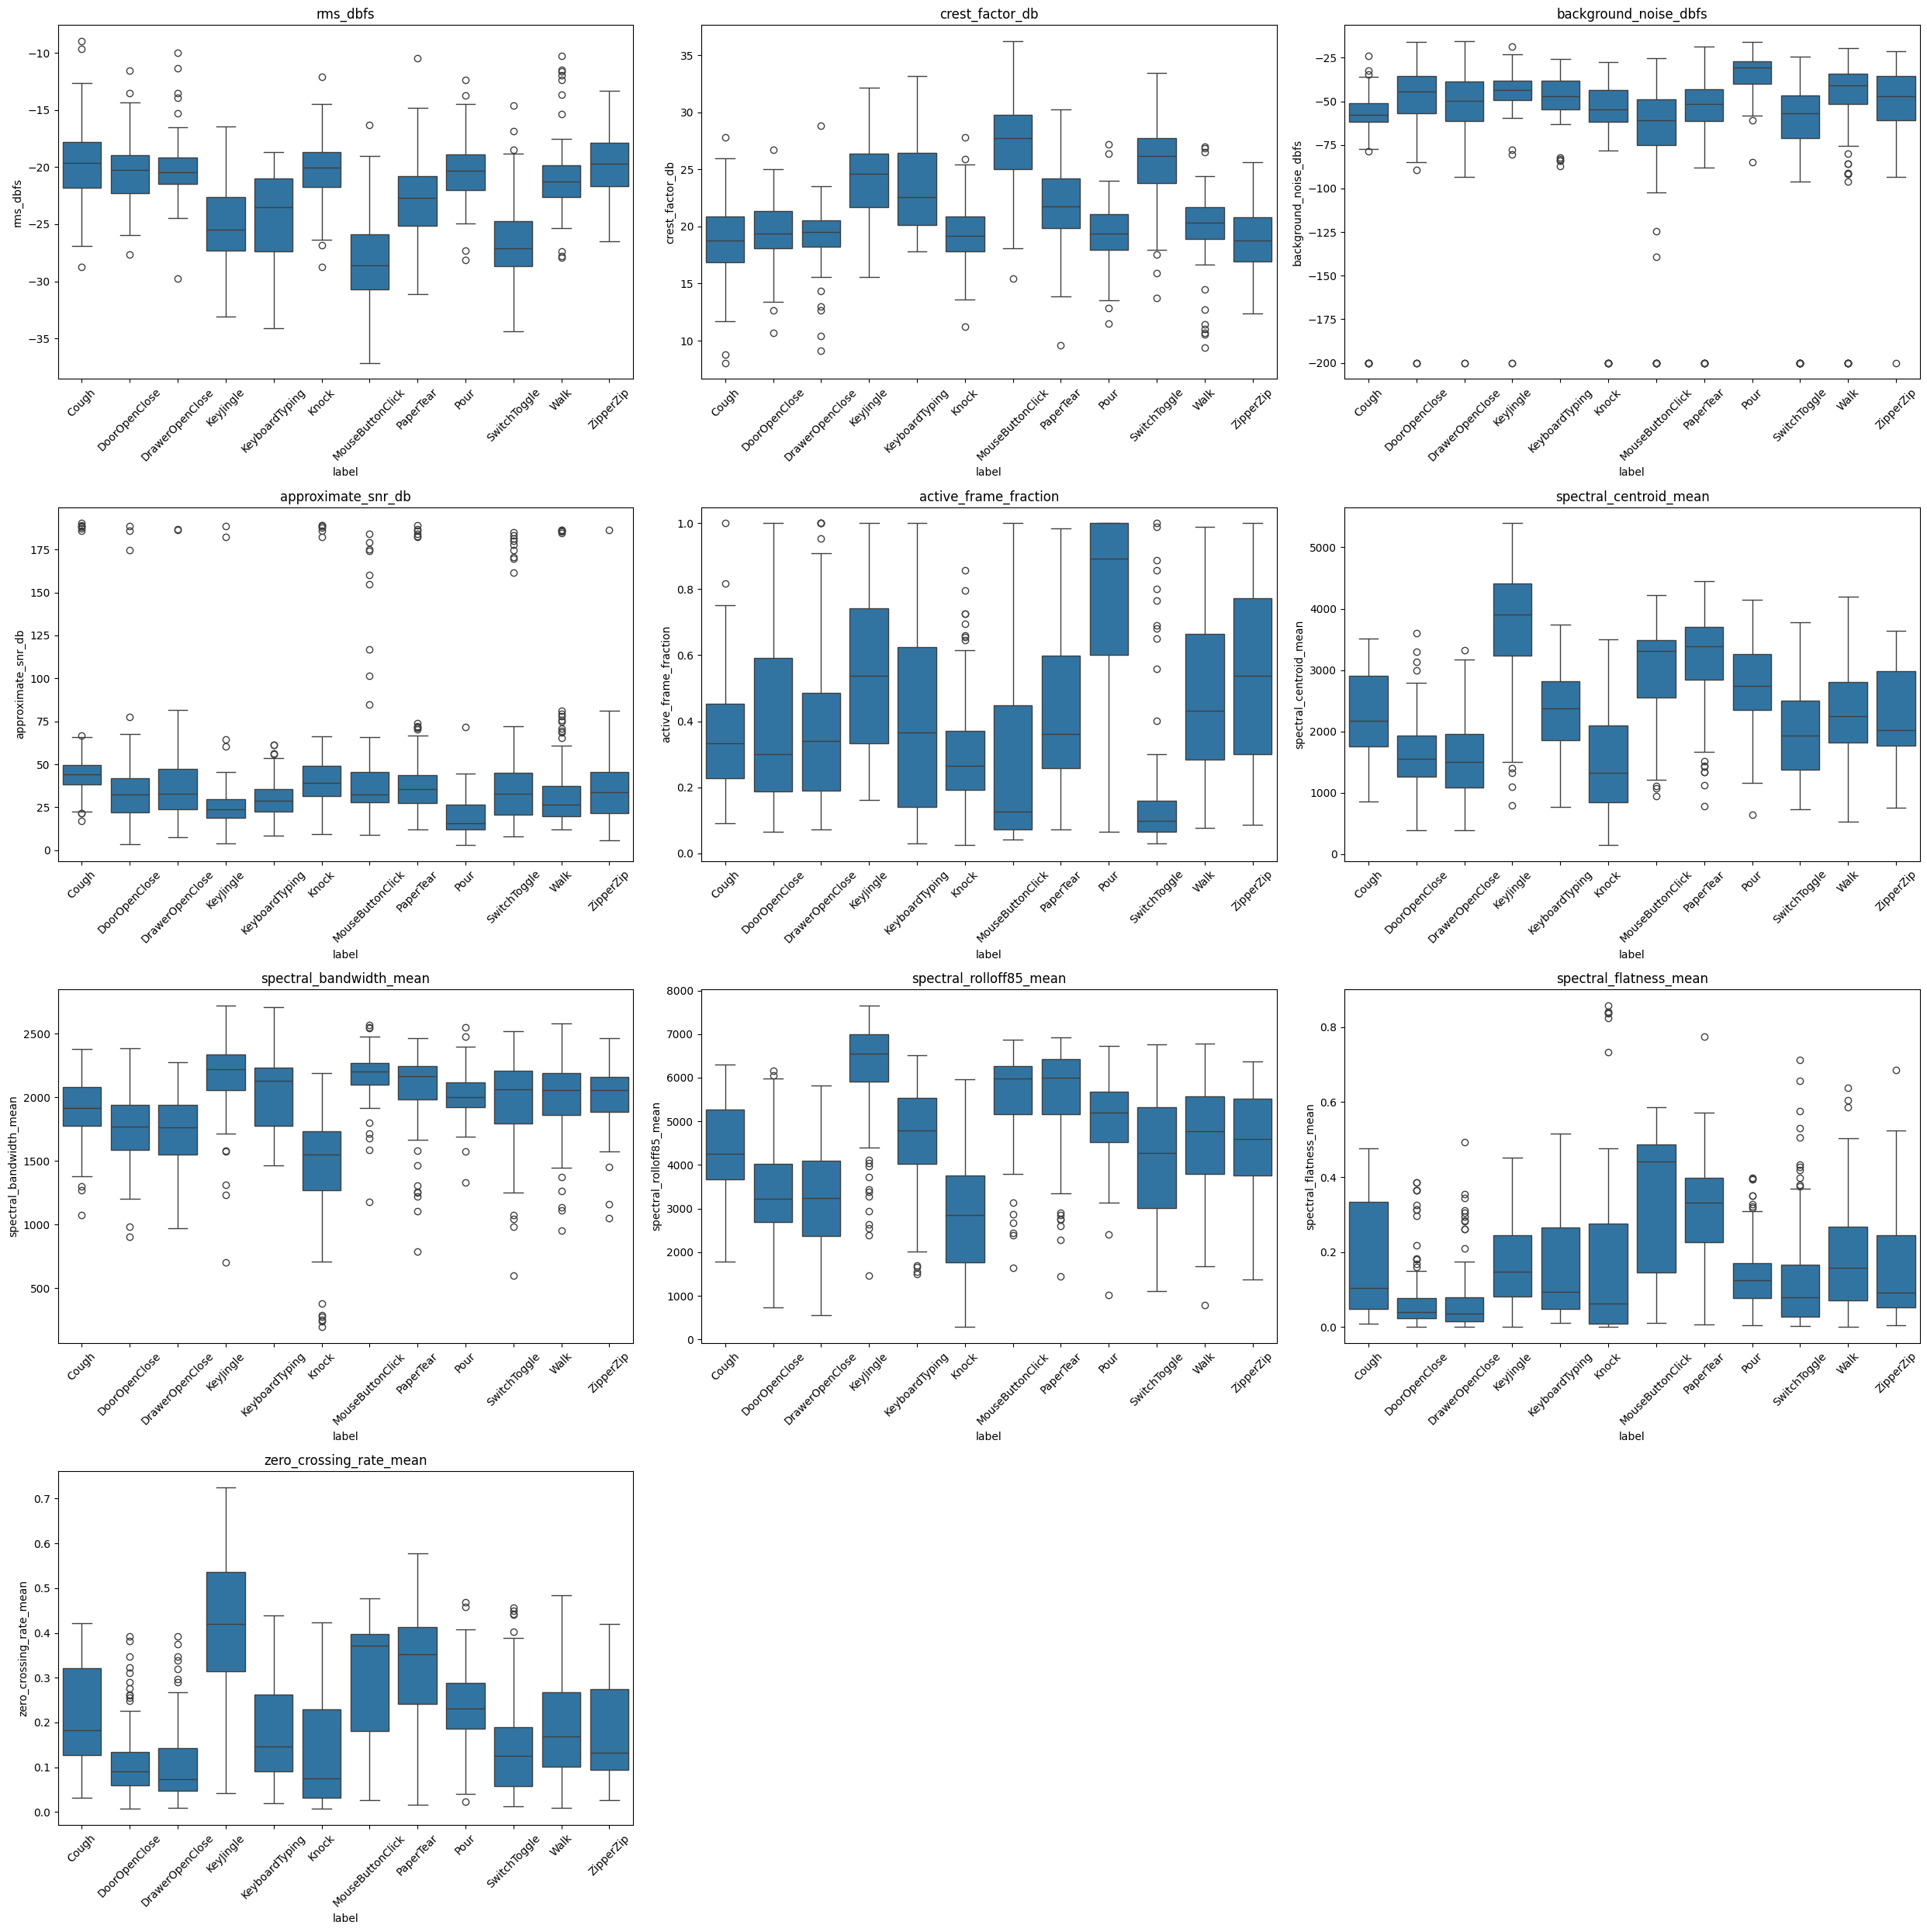

In [8]:
plt.figure(figsize=(25, 25))
for i, col in enumerate(analyzed_features):
    ax = plt.subplot(4, 3, i+1)
    sns.boxplot(data=train_df, x="label", y=col, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

`rms_dbfs` and `crest_factor_db`: MouseButtonClick and SwitchToggle have some of the lowest median RMS levels, but some of the highest median crest factors. This suggests that their peaks are strong relative to their overall level. However, the distributions overlap substantially, so neither feature reliably separates the classes on its own.

`background_noise_dbfs` and `approximate_snr_db`: Pour has the highest median background-noise level and the lowest median approximate SNR. These features provide only weak separation between classes.

`active_frame_fraction`: Pour has the highest median value, while SwitchToggle has the lowest one.

`spectral_centroid_mean`: KeyJingle has the highest median spectral centroid, while MouseButtonClick and PaperTear also show relatively high values. This feature may help distinguish KeyJingle from most other classes, although the distributions overlap and it cannot separate all classes on its own.

`spectral_bandwidth_mean`: This feature best separates Knock from the other classes.

`spectral_rolloff85_mean`: KeyJingle has the highest median, while MouseButtonClick and PaperTear also show relatively high values. This feature may help distinguish KeyJingle from many classes, but the distributions overlap.

`spectral_flatness_mean`: MouseButtonClick has the highest median spectral flatness, followed by PaperTear.

`zero_crossing_rate_mean`: KeyJingle has the highest median value, with MouseButtonClick and PaperTear also showing high values. This feature may help distinguish these classes from several others, but it does not clearly separate all classes.

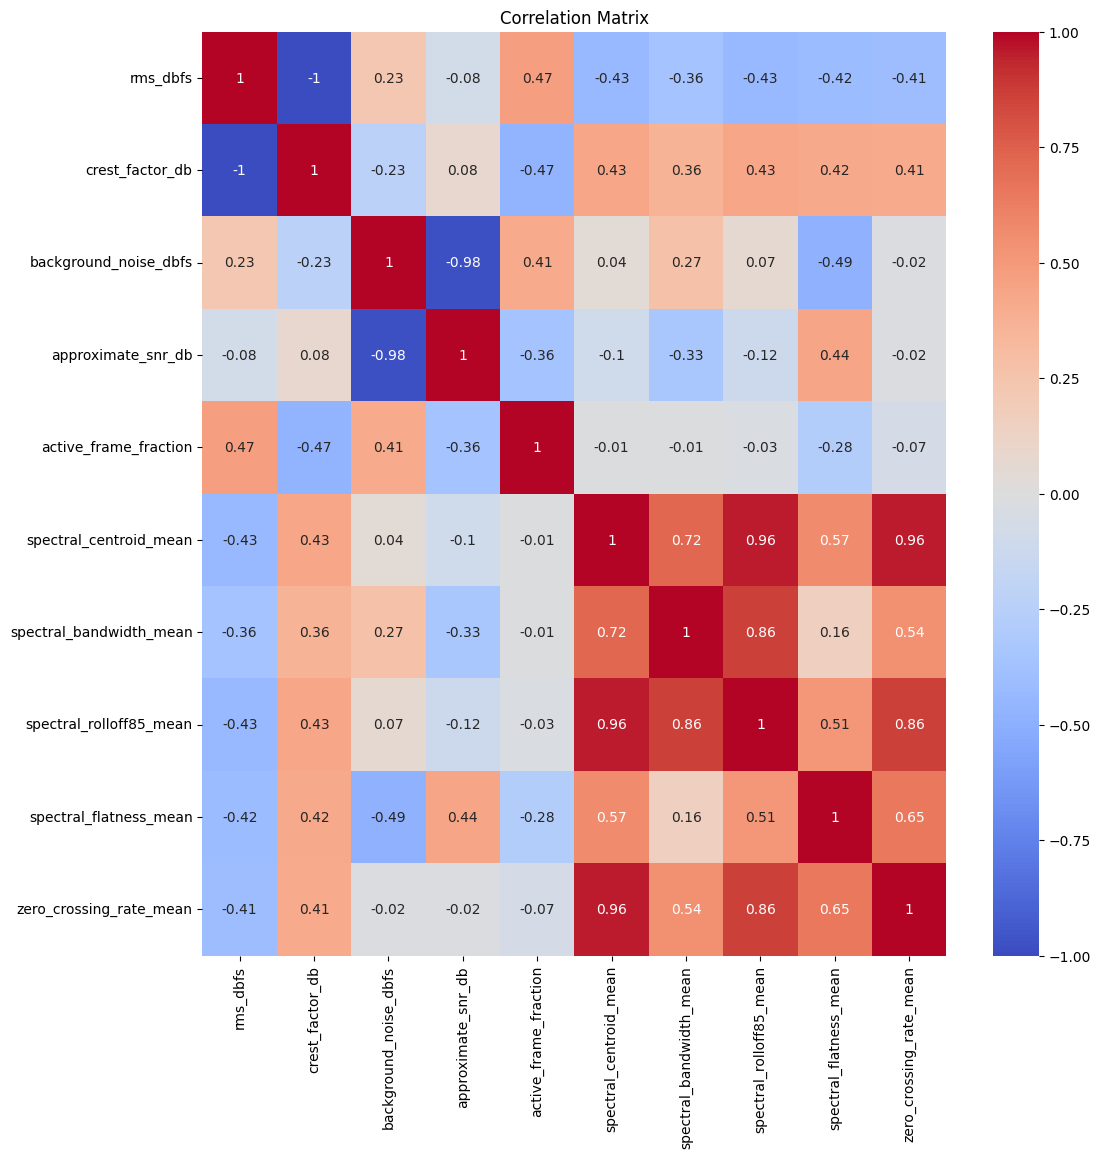

In [9]:
plt.figure(figsize=(12, 12))
sns.heatmap(round(train_df[analyzed_features].corr(),2), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

There is a perfect negative correlation between `rms_dbfs` and `crest_factor_db`. This is expected because the clips are normalized based on the value of the peak. There is also a high inverse correlation between `background_noise_dbfs` and `approximate_snr_db`. Strong positive correlations are observed between `spectral_centroid_mean`, `spectral_rolloff85_mean`, and `zero_crossing_rate_mean` (r = 0.86–0.96). `spectral_bandwidth_mean` is also correlated with `spectral_rolloff85_mean` (r = 0.86) and `spectral_centroid_mean` (r = 0.72). These correlations suggest some redundancy among features.

In [10]:
mcff_cols = [col for col in feature_names if "mfcc" in col]
pca_ready = train_df[mcff_cols]

scaler = StandardScaler()
pca_ready = scaler.fit_transform(pca_ready)

pca = PCA()
train_pca_fitted = pca.fit_transform(pca_ready)

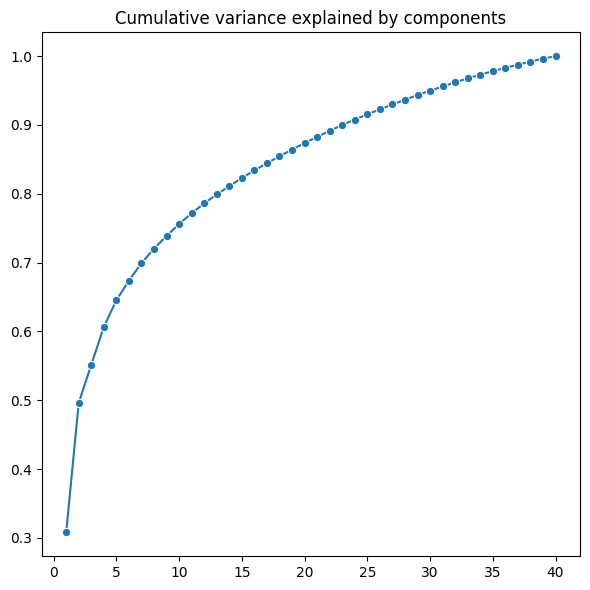

In [11]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(6,6))
sns.lineplot(x= range(1,len(cumulative_variance)+1), y=cumulative_variance, ax=ax, marker='o')
plt.title(f'Cumulative variance explained by components')
plt.tight_layout()
plt.show()

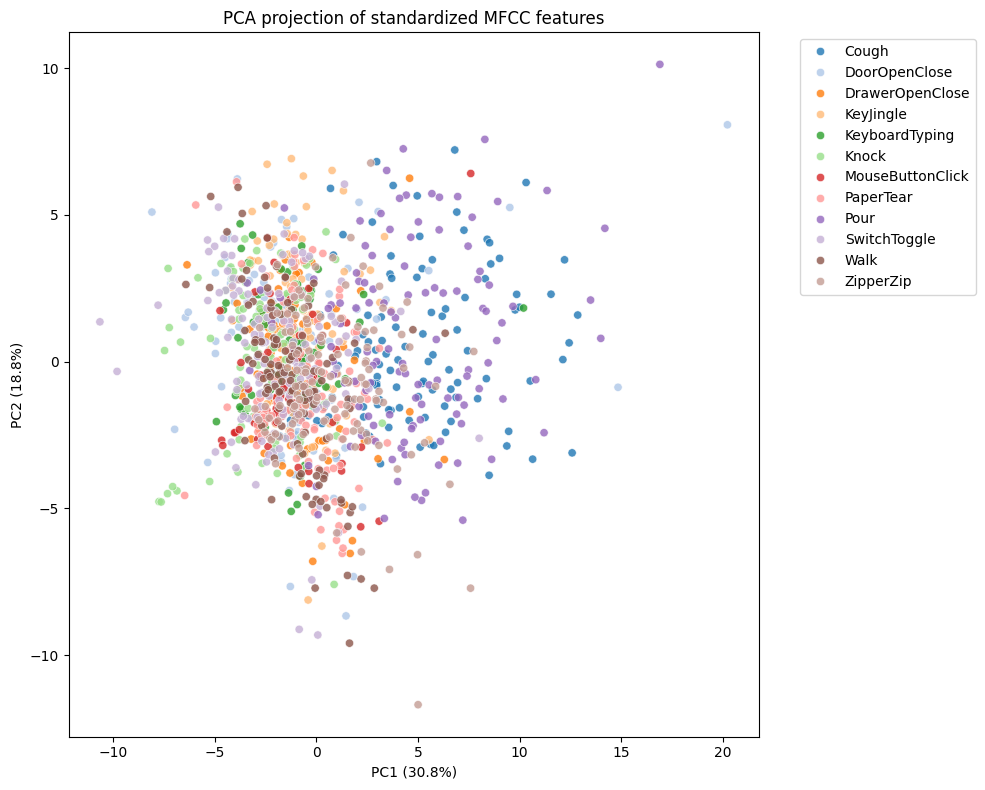

In [12]:
pca_plot = pd.DataFrame({
    "PC1": train_pca_fitted[:, 0],
    "PC2": train_pca_fitted[:, 1],
    "label": train_df["label"].to_numpy()
})

plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=pca_plot,
    x="PC1",
    y="PC2",
    hue="label",
    palette="tab20",
    alpha=0.8
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
plt.title("PCA projection of standardized MFCC features")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

The first two principal components explain 49.6% of the variance. Most classes overlap substantially around the center of the projection, and no clear class-specific clusters are visible. This suggests that the first two principal components do not separate the classes well visually. In order to explain 80% of the variance, 14 principal components are required.

### SVM

In [13]:
preprocessor = ColumnTransformer([
    ("mfcc", Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=14))
    ]), mcff_cols),
    ("descriptors", "passthrough", analyzed_features)
])

group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

input_cols = list(analyzed_features) + list(mcff_cols)

In [14]:
svc = Pipeline([
    ("features", preprocessor),
    ("scaler", StandardScaler()),
    ("svc", SVC(class_weight="balanced", random_state=42))
])

params = {
    "svc__C": [0.1, 1, 10, 15, 20],
    "svc__kernel": ["linear", "rbf"],
    "svc__gamma": ["scale", "auto"]
}

clf = RandomizedSearchCV(
    estimator=svc,
    param_distributions=params,
    n_iter=16,
    cv=group_cv,
    scoring="f1_macro",
    random_state=42
)

search1 = clf.fit(
    train_df[input_cols],
    y_train,
    groups=train_df["source_id"]
)

print("Best parameters: ", search1.best_params_)
print("Best score: ", search1.best_score_)

results = pd.DataFrame(search1.cv_results_)

cols = [
    "param_svc__C",
    "param_svc__kernel",
    "param_svc__gamma",
    "mean_test_score",
    "rank_test_score"
]

display(results[cols].sort_values("rank_test_score"))

Best parameters:  {'svc__kernel': 'rbf', 'svc__gamma': 'auto', 'svc__C': 15}
Best score:  0.5736071312141208


,param_svc__C,param_svc__kernel,param_svc__gamma,mean_test_score,rank_test_score
2,15.0,rbf,auto,0.573607,1
10,15.0,rbf,scale,0.573607,1
12,10.0,rbf,scale,0.568522,3
6,10.0,rbf,auto,0.568522,3
1,20.0,rbf,scale,0.562373,5
13,20.0,rbf,auto,0.562373,5
5,1.0,rbf,scale,0.556907,7
14,1.0,linear,scale,0.546707,8
4,10.0,linear,scale,0.532861,9
11,0.1,linear,auto,0.530731,10


Mean cross-validation macro F1 ranged from 0.451 to 0.574. The RBF kernel performed best at `C=15`, but it scored below the linear kernel at `C=0.1`. The two `gamma` settings gave identical scores wherever both were tested.

In [15]:
class_names = sorted(y_train.unique())

def evaluate_split(model, X, y):
    y_pred = model.predict(X)

    print(f"Accuracy: {accuracy_score(y, y_pred):.3f}")
    print(f"F1-macro: {f1_score(y, y_pred, average='macro'):.3f}")
    print(classification_report(
        y, y_pred, labels=class_names,
        target_names=class_names, zero_division=0
    ))

    cm = confusion_matrix(y, y_pred, labels=class_names)

    plt.figure(figsize=(12, 12))
    sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.title("Confusion matrix")
    plt.xticks(rotation=45)
    plt.show()

#### Validation Set Results

Accuracy: 0.610
F1-macro: 0.571
                  precision    recall  f1-score   support

           Cough       0.73      0.73      0.73        15
   DoorOpenClose       0.47      0.53      0.50        15
 DrawerOpenClose       0.46      0.50      0.48        12
       KeyJingle       0.75      0.90      0.82        10
  KeyboardTyping       0.00      0.00      0.00         8
           Knock       0.83      0.83      0.83        12
MouseButtonClick       0.18      0.25      0.21         8
       PaperTear       0.63      0.86      0.73        14
            Pour       0.92      0.80      0.86        15
    SwitchToggle       0.69      0.73      0.71        15
            Walk       0.64      0.47      0.54        15
       ZipperZip       0.50      0.40      0.44        15

        accuracy                           0.61       154
       macro avg       0.57      0.58      0.57       154
    weighted avg       0.60      0.61      0.60       154



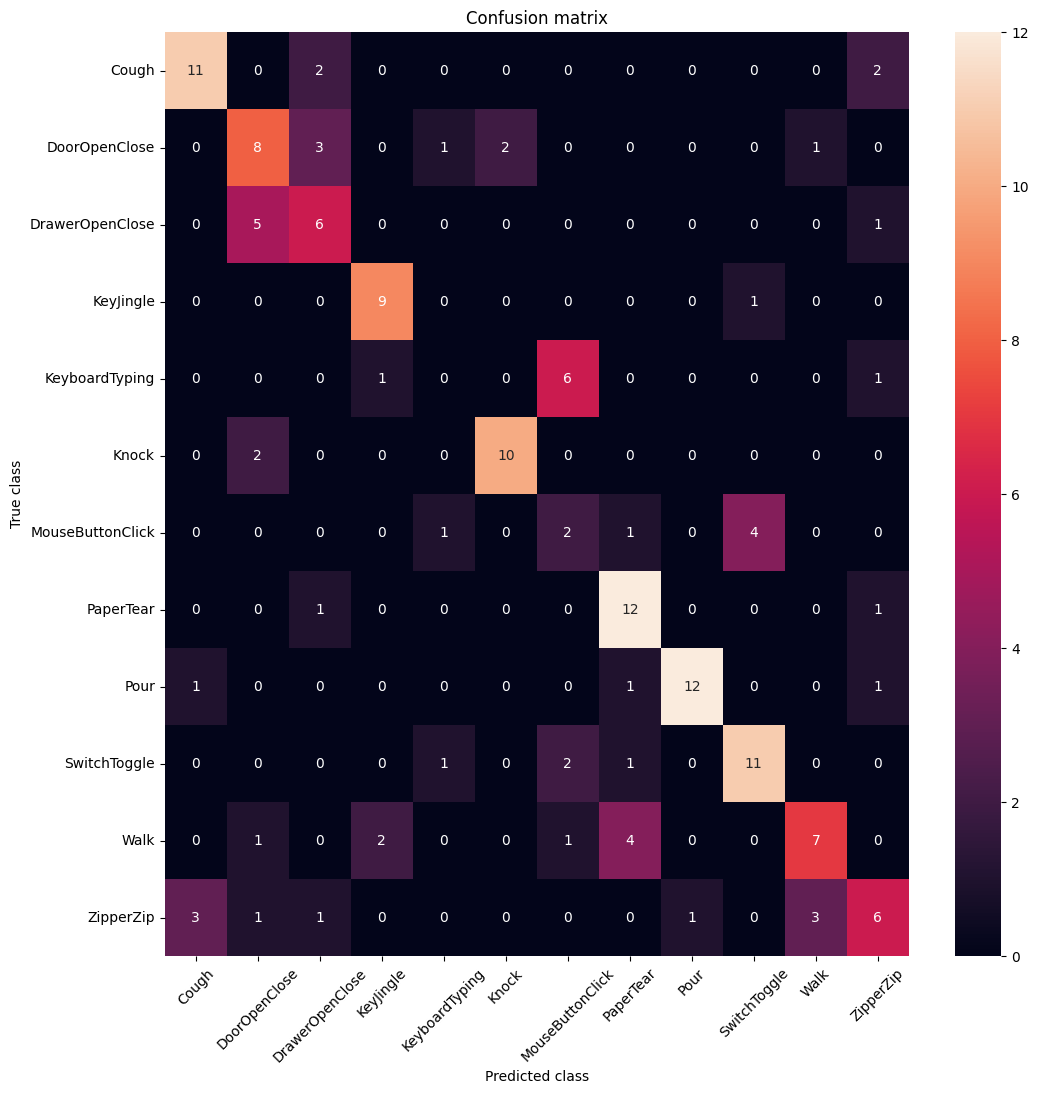

In [16]:
evaluate_split(search1.best_estimator_, X_val, y_val)

#### Test Set Results

Accuracy: 0.597
F1-macro: 0.582
                  precision    recall  f1-score   support

           Cough       0.59      0.67      0.62        15
   DoorOpenClose       0.33      0.47      0.39        15
 DrawerOpenClose       0.55      0.55      0.55        11
       KeyJingle       0.58      0.64      0.61        11
  KeyboardTyping       0.57      0.44      0.50         9
           Knock       0.86      0.92      0.89        13
MouseButtonClick       0.43      0.43      0.43         7
       PaperTear       0.60      0.69      0.64        13
            Pour       0.88      0.93      0.90        15
    SwitchToggle       0.73      0.73      0.73        15
            Walk       0.38      0.20      0.26        15
       ZipperZip       0.55      0.40      0.46        15

        accuracy                           0.60       154
       macro avg       0.59      0.59      0.58       154
    weighted avg       0.59      0.60      0.59       154



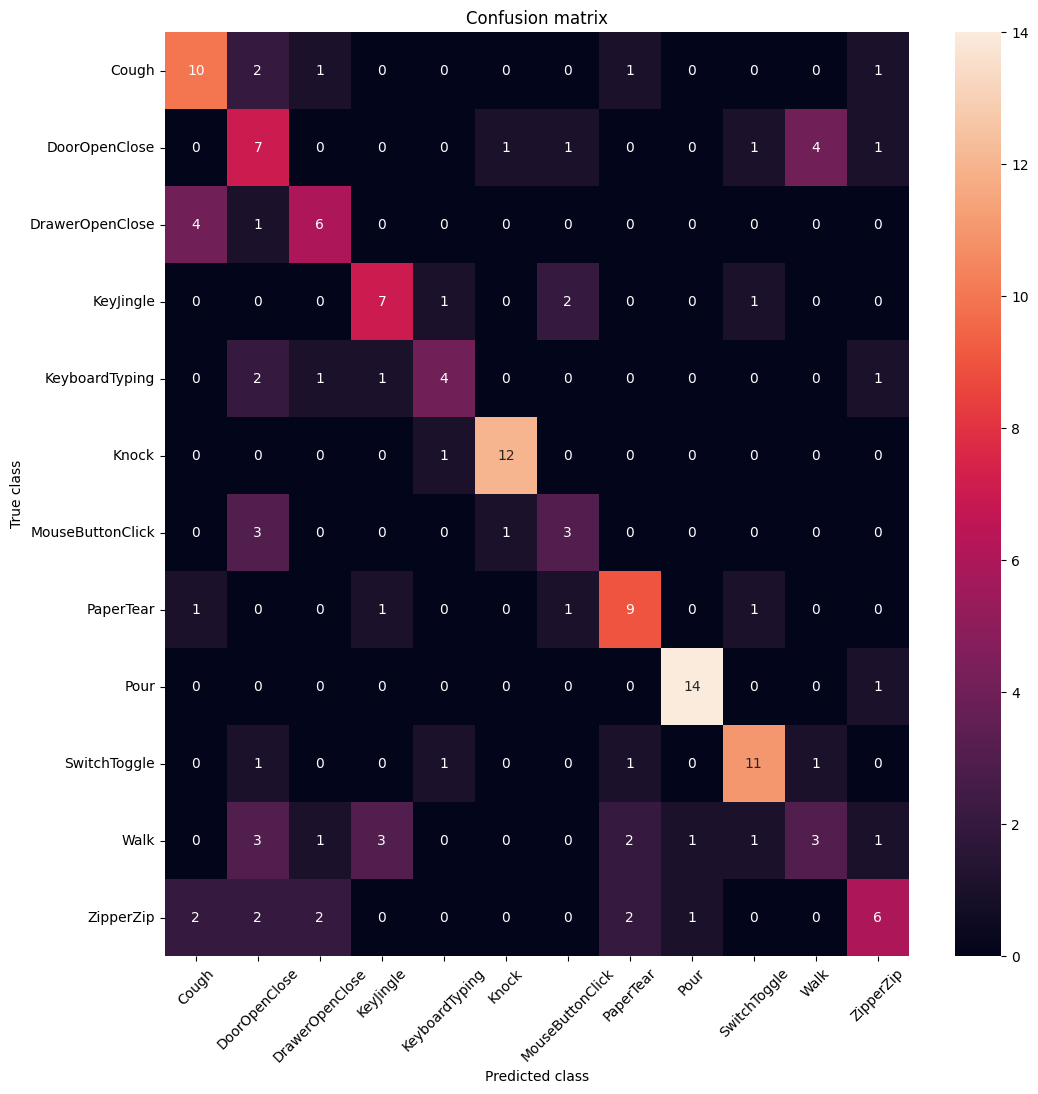

In [17]:
evaluate_split(search1.best_estimator_, X_test, y_test)

## RandomForestClassifier

In [18]:
rfc = Pipeline([
    ("features", preprocessor),
    ("rfc", RandomForestClassifier(class_weight="balanced", n_estimators=200, random_state=42))
])

params = {
    "rfc__criterion": ["entropy", "log_loss"],
    "rfc__max_depth": [10, 12],
    "rfc__min_samples_split": [10, 14]
}

clf = RandomizedSearchCV(
    estimator=rfc,
    param_distributions=params,
    n_iter=8,
    cv=group_cv,
    scoring="f1_macro",
    random_state=42
)

search2 = clf.fit(
    train_df[input_cols],
    y_train,
    groups=train_df["source_id"]
)

print("Best parameters: ", search2.best_params_)
print("Best score: ", search2.best_score_)

results = pd.DataFrame(search2.cv_results_)

cols = [
    "param_rfc__criterion",
    "param_rfc__max_depth",
    "param_rfc__min_samples_split",
    "mean_test_score",
    "rank_test_score"
]

display(results[cols].sort_values("rank_test_score"))

Best parameters:  {'rfc__min_samples_split': 10, 'rfc__max_depth': 12, 'rfc__criterion': 'entropy'}
Best score:  0.5567125305484264


,param_rfc__criterion,param_rfc__max_depth,param_rfc__min_samples_split,mean_test_score,rank_test_score
2,entropy,12,10,0.556713,1
6,log_loss,12,10,0.556713,1
4,log_loss,10,10,0.556092,3
0,entropy,10,10,0.556092,3
5,log_loss,10,14,0.548600,5
1,entropy,10,14,0.548600,5
3,entropy,12,14,0.546104,7
7,log_loss,12,14,0.546104,7


Scores varied little across the tested configurations, from 0.546 to 0.557. `min_samples_split=10` consistently scored higher than `14` in matched comparisons, while `entropy` and `log_loss` gave similar scores.

#### Validation Set Results

Accuracy: 0.532
F1-macro: 0.495
                  precision    recall  f1-score   support

           Cough       0.83      0.67      0.74        15
   DoorOpenClose       0.43      0.40      0.41        15
 DrawerOpenClose       0.42      0.42      0.42        12
       KeyJingle       0.70      0.70      0.70        10
  KeyboardTyping       0.00      0.00      0.00         8
           Knock       0.83      0.83      0.83        12
MouseButtonClick       0.20      0.12      0.15         8
       PaperTear       0.47      0.57      0.52        14
            Pour       0.75      0.80      0.77        15
    SwitchToggle       0.61      0.73      0.67        15
            Walk       0.33      0.47      0.39        15
       ZipperZip       0.33      0.33      0.33        15

        accuracy                           0.53       154
       macro avg       0.49      0.50      0.49       154
    weighted avg       0.52      0.53      0.52       154



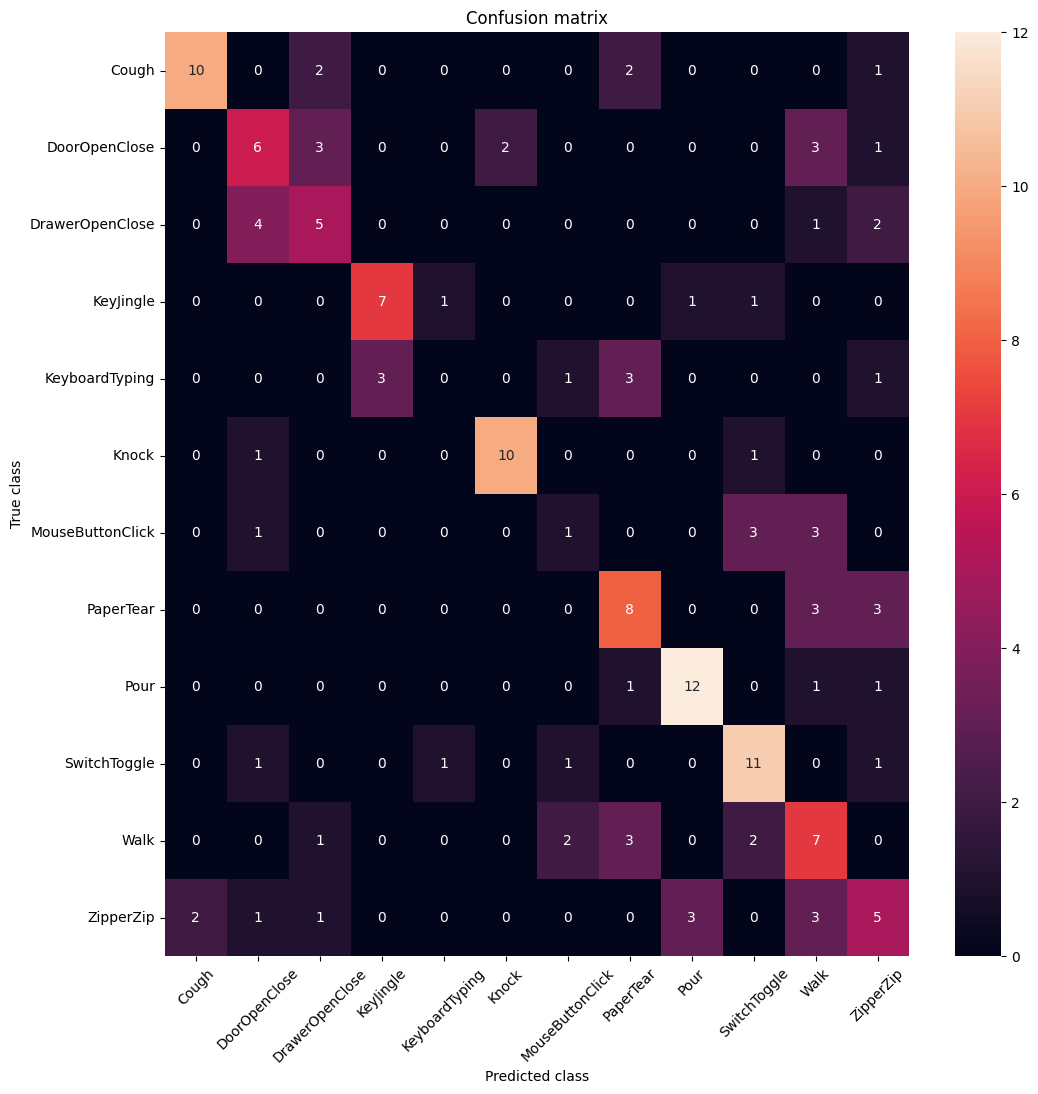

In [19]:
evaluate_split(search2.best_estimator_, X_val, y_val)

#### Test Set Results

Accuracy: 0.552
F1-macro: 0.525
                  precision    recall  f1-score   support

           Cough       0.69      0.73      0.71        15
   DoorOpenClose       0.18      0.20      0.19        15
 DrawerOpenClose       0.36      0.45      0.40        11
       KeyJingle       0.90      0.82      0.86        11
  KeyboardTyping       0.50      0.11      0.18         9
           Knock       0.63      0.92      0.75        13
MouseButtonClick       0.43      0.43      0.43         7
       PaperTear       0.50      0.38      0.43        13
            Pour       0.59      0.87      0.70        15
    SwitchToggle       0.69      0.73      0.71        15
            Walk       0.60      0.40      0.48        15
       ZipperZip       0.55      0.40      0.46        15

        accuracy                           0.55       154
       macro avg       0.55      0.54      0.53       154
    weighted avg       0.55      0.55      0.54       154



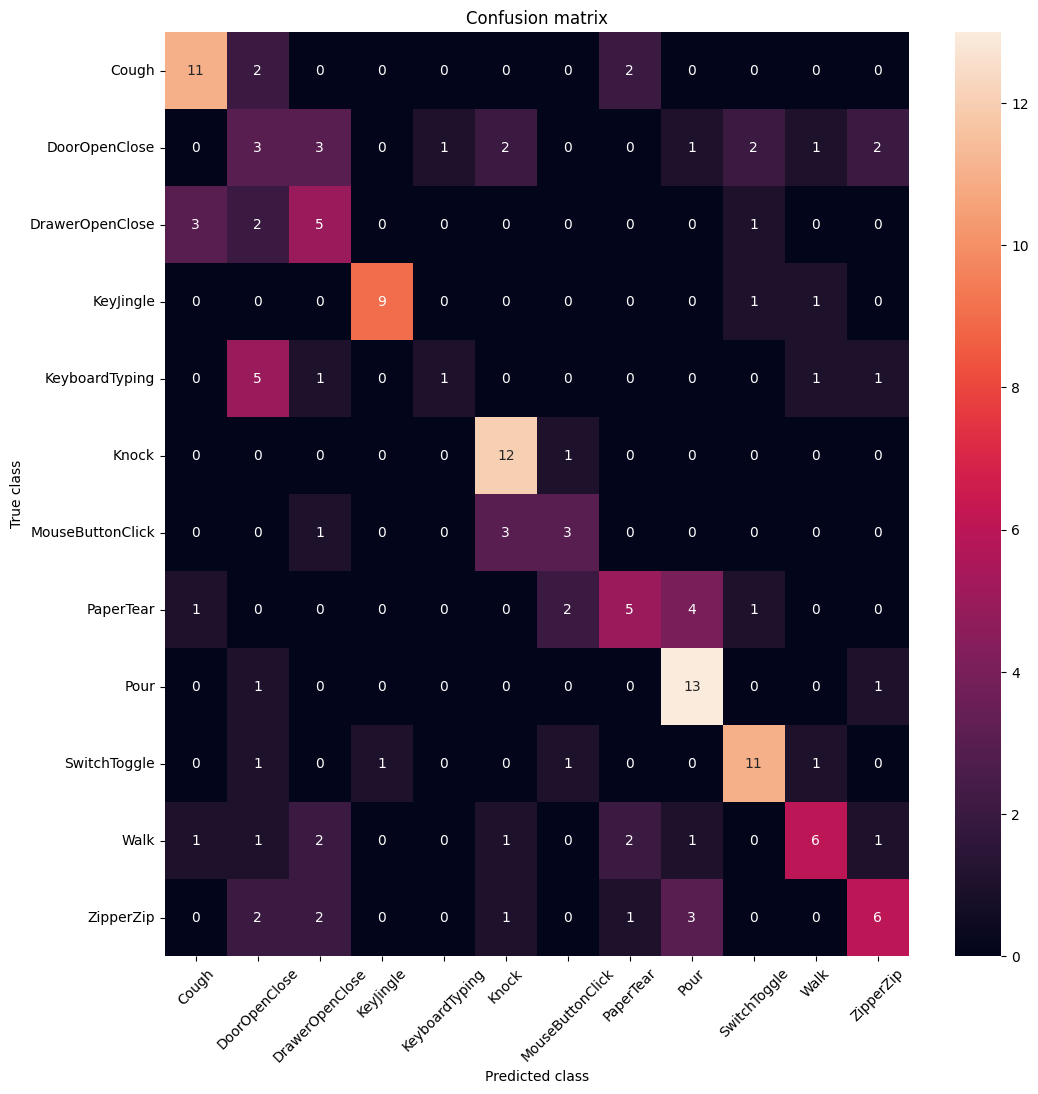

In [20]:
evaluate_split(search2.best_estimator_, X_test, y_test)

## GradientBoostingClassifier

In [21]:
gbc = Pipeline([
    ("features", preprocessor),
    ("gbc", GradientBoostingClassifier(random_state=42))
])

params = {
    "gbc__max_depth": [3],
    "gbc__n_estimators": [100, 50],
    "gbc__subsample": [0.8],
    "gbc__learning_rate": [0.1, 0.2]
}

clf = RandomizedSearchCV(
    estimator=gbc,
    param_distributions=params,
    n_iter=4,
    cv=group_cv,
    scoring="f1_macro",
    random_state=42, 
    verbose=3
)

search3 = clf.fit(
    train_df[input_cols],
    y_train,
    groups=train_df["source_id"]
)

print("Best parameters: ", search3.best_params_)
print("Best score: ", search3.best_score_)

results = pd.DataFrame(search3.cv_results_)

cols = [
    "param_gbc__n_estimators",
    "param_gbc__max_depth",
    "param_gbc__subsample",
    "param_gbc__learning_rate",
    "mean_test_score",
    "rank_test_score"
]

display(results[cols].sort_values("rank_test_score"))

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV 1/5] END gbc__learning_rate=0.1, gbc__max_depth=3, gbc__n_estimators=100, gbc__subsample=0.8;, score=0.587 total time=  10.9s
[CV 2/5] END gbc__learning_rate=0.1, gbc__max_depth=3, gbc__n_estimators=100, gbc__subsample=0.8;, score=0.553 total time=   7.8s
[CV 3/5] END gbc__learning_rate=0.1, gbc__max_depth=3, gbc__n_estimators=100, gbc__subsample=0.8;, score=0.583 total time=   7.9s
[CV 4/5] END gbc__learning_rate=0.1, gbc__max_depth=3, gbc__n_estimators=100, gbc__subsample=0.8;, score=0.509 total time=   9.6s
[CV 5/5] END gbc__learning_rate=0.1, gbc__max_depth=3, gbc__n_estimators=100, gbc__subsample=0.8;, score=0.549 total time=   8.7s
[CV 1/5] END gbc__learning_rate=0.1, gbc__max_depth=3, gbc__n_estimators=50, gbc__subsample=0.8;, score=0.570 total time=   4.9s
[CV 2/5] END gbc__learning_rate=0.1, gbc__max_depth=3, gbc__n_estimators=50, gbc__subsample=0.8;, score=0.535 total time=   4.6s
[CV 3/5] END gbc__learning_rate=

,param_gbc__n_estimators,param_gbc__max_depth,param_gbc__subsample,param_gbc__learning_rate,mean_test_score,rank_test_score
0,100,3,0.8,0.1,0.556186,1
1,50,3,0.8,0.1,0.541581,2
2,100,3,0.8,0.2,0.539800,3
3,50,3,0.8,0.2,0.520519,4


Scores ranged from 0.521 to 0.556. Using 100 estimators instead of 50 improved the score at both learning rates, and `learning_rate=0.1` did better than `0.2` at both estimator counts.

#### Validation Set Results

Accuracy: 0.506
F1-macro: 0.479
                  precision    recall  f1-score   support

           Cough       0.79      0.73      0.76        15
   DoorOpenClose       0.44      0.53      0.48        15
 DrawerOpenClose       0.57      0.33      0.42        12
       KeyJingle       0.71      0.50      0.59        10
  KeyboardTyping       0.33      0.12      0.18         8
           Knock       0.67      0.83      0.74        12
MouseButtonClick       0.25      0.12      0.17         8
       PaperTear       0.38      0.36      0.37        14
            Pour       0.71      0.67      0.69        15
    SwitchToggle       0.53      0.67      0.59        15
            Walk       0.44      0.53      0.48        15
       ZipperZip       0.23      0.33      0.27        15

        accuracy                           0.51       154
       macro avg       0.51      0.48      0.48       154
    weighted avg       0.51      0.51      0.50       154



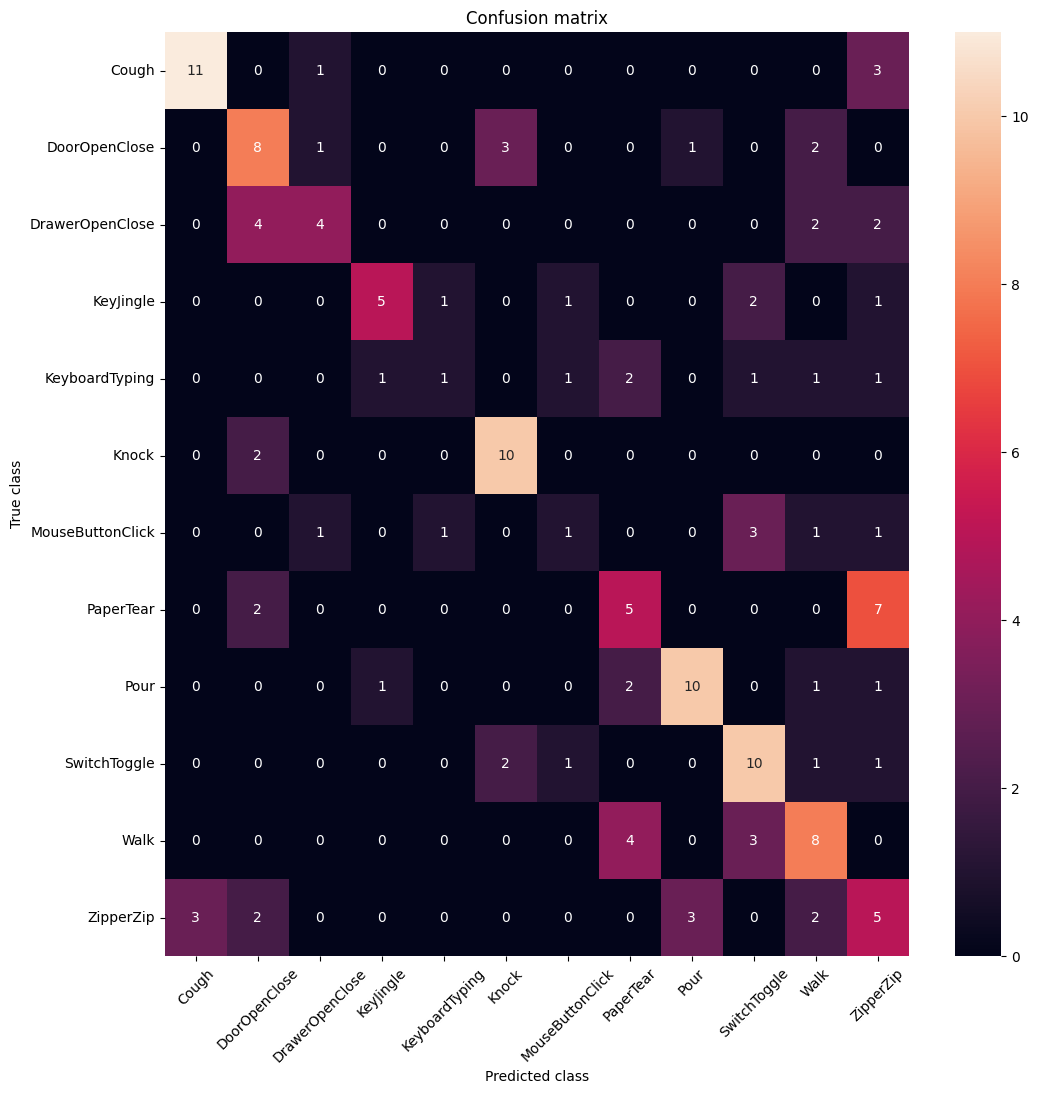

In [22]:
evaluate_split(search3.best_estimator_, X_val, y_val)

#### Test Set Results

Accuracy: 0.539
F1-macro: 0.499
                  precision    recall  f1-score   support

           Cough       0.59      0.67      0.62        15
   DoorOpenClose       0.32      0.53      0.40        15
 DrawerOpenClose       0.40      0.18      0.25        11
       KeyJingle       0.89      0.73      0.80        11
  KeyboardTyping       0.25      0.11      0.15         9
           Knock       0.72      1.00      0.84        13
MouseButtonClick       0.43      0.43      0.43         7
       PaperTear       0.20      0.08      0.11        13
            Pour       0.72      0.87      0.79        15
    SwitchToggle       0.79      0.73      0.76        15
            Walk       0.44      0.47      0.45        15
       ZipperZip       0.38      0.40      0.39        15

        accuracy                           0.54       154
       macro avg       0.51      0.52      0.50       154
    weighted avg       0.52      0.54      0.52       154



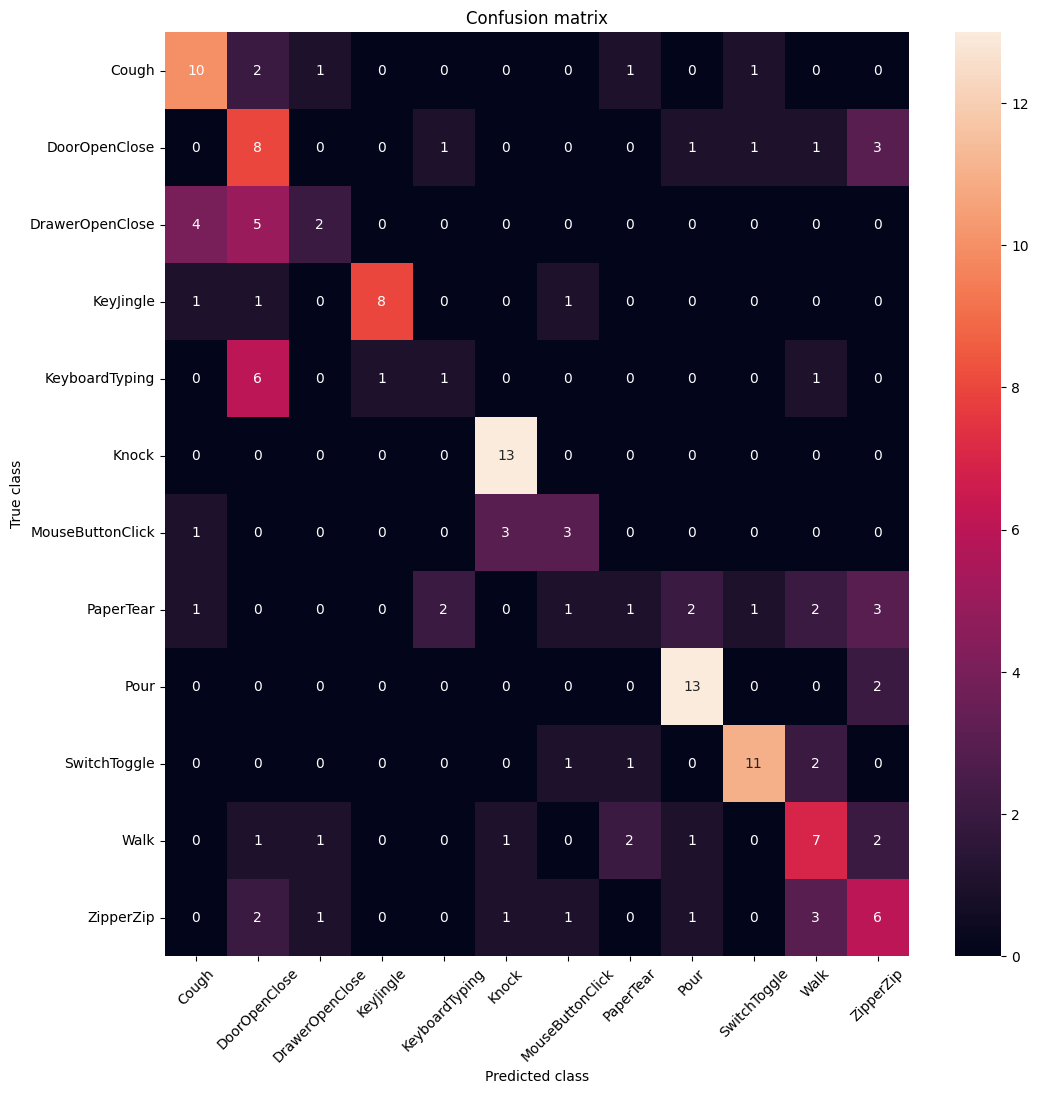

In [23]:
evaluate_split(search3.best_estimator_, X_test, y_test)

SVM achieved the highest validation macro F1 (0.571), compared with 0.495 for RandomForestClassifier, which had the second highest value, and 0.479 for GradientBoostingClassifier, which was last. On the test set, the ranking stayed the same: SVM with a macro F1 of 0.582, RandomForestClassifier with 0.525 and GradientBoostingClassifier with 0.499. 

On the validation set, SVM misclassifies `KeyboardTyping` often as being `MouseButtonClick`. This is not unusual, since these sounds share similarities. 

RandomForestClassifier does not correctly identify any of the `KeyboardTyping` in the validation set. This could happen due to the fact that the class mentioned before is a minority class. In the testing set, the same model often misclassifies `KeyboardTyping` as `DoorOpenClose`. 

GradientBoostingClassifier tended to predict `ZipperZip` for `PaperTear` clips. The distributions of mean spectral bandwidth and background noise overlap for these two classes, which may partly explain the confusion. Gradient Boosting achieved a mean cross-validation macro F1 of 0.556 and a macro F1 of 0.479 on the separate validation set.

## Different distribution

Accuracy: 0.575
F1-macro: 0.521
                  precision    recall  f1-score   support

           Cough       0.64      0.70      0.67        10
   DoorOpenClose       0.20      0.50      0.29        10
 DrawerOpenClose       0.54      0.70      0.61        10
       KeyJingle       0.82      0.90      0.86        10
  KeyboardTyping       0.71      1.00      0.83        10
           Knock       0.91      1.00      0.95        10
MouseButtonClick       0.00      0.00      0.00        10
       PaperTear       0.00      0.00      0.00        10
            Pour       1.00      0.80      0.89        10
    SwitchToggle       0.62      1.00      0.77        10
            Walk       0.33      0.10      0.15        10
       ZipperZip       0.29      0.20      0.24        10

        accuracy                           0.57       120
       macro avg       0.51      0.57      0.52       120
    weighted avg       0.51      0.57      0.52       120



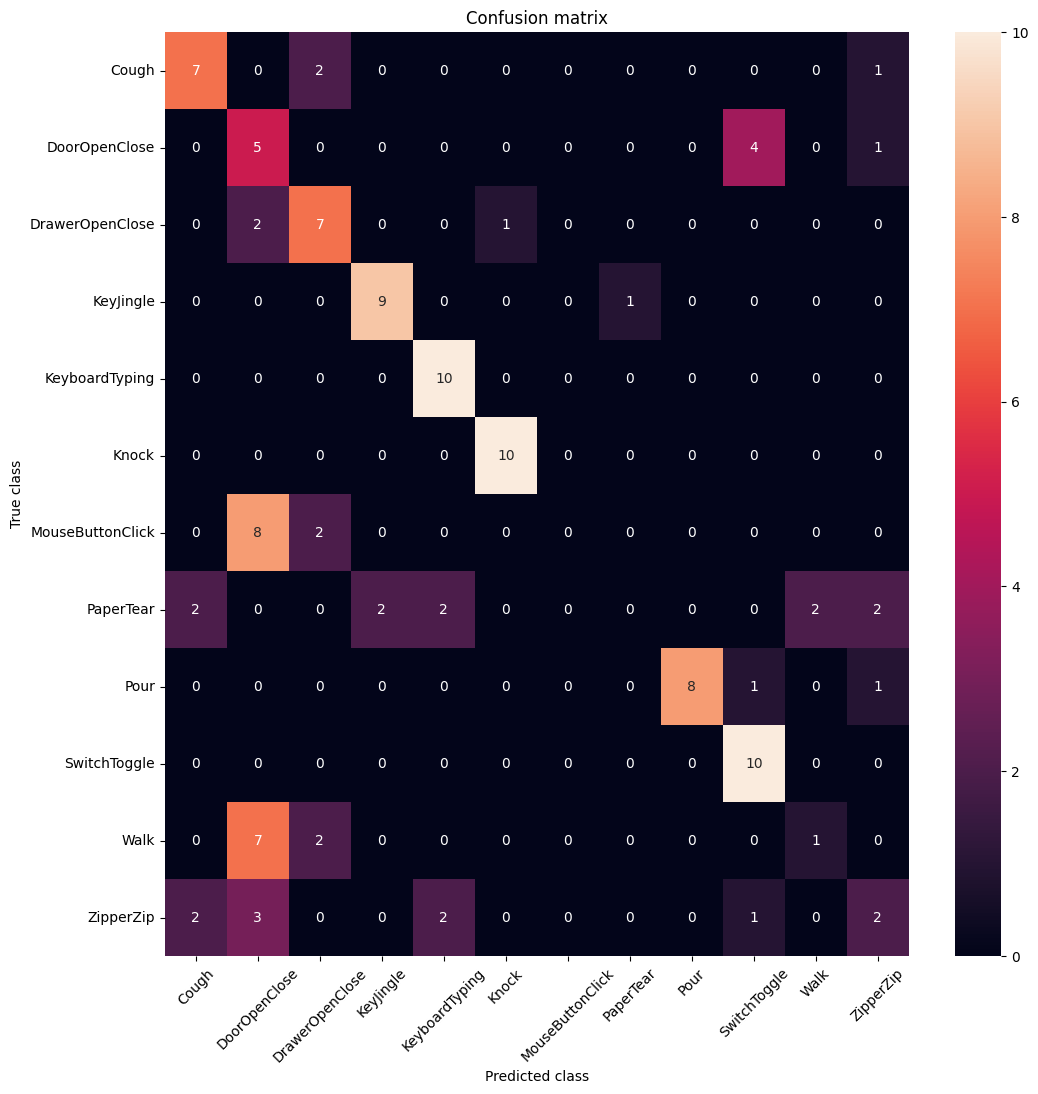

In [27]:
my_feature_rows = []
output_dir = Path("my_recordings")
my_metadata = pd.read_csv(output_dir / "metadata.csv")

for filename in my_metadata["filename"]:
    audio, sr = sf.read(output_dir / filename, dtype="float32")
    my_feature_rows.append(extract_features(audio))

X_my = pd.DataFrame(my_feature_rows, columns=feature_names)
y_my = my_metadata["label"]

evaluate_split(search1.best_estimator_, X_my[input_cols], y_my)

On my recordings, SVM achieved 0.575 accuracy and a macro F1 of 0.521. Macro F1 was 0.061 lower than on the initial test set (0.582).

The model correctly recognized all 10 recordings in each of the `KeyboardTyping`, `Knock`, and `SwitchToggle` classes. It did not correctly recognize any `MouseButtonClick` or `PaperTear` recordings. `DoorOpenClose` was a frequent incorrect prediction, accounting for 8 of the 10 `MouseButtonClick` clips and 7 of the 10 `Walk` clips. 

The test confusion matrix for SVM has more spread out errors and does not exhibit a clear tendency to misclassify one thing as another, as does the data collected by me.

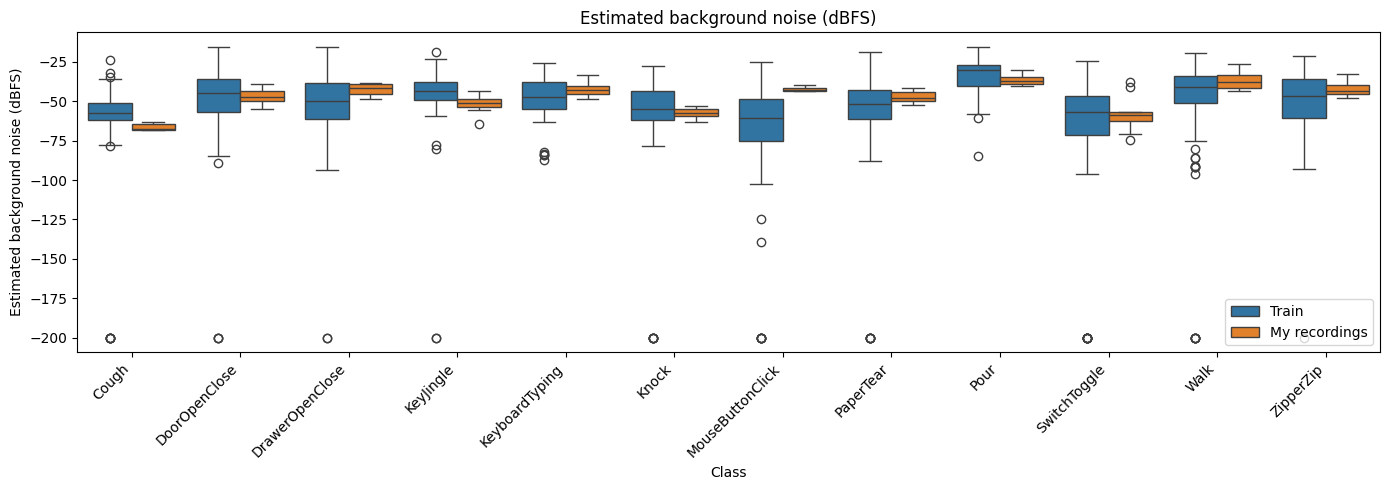

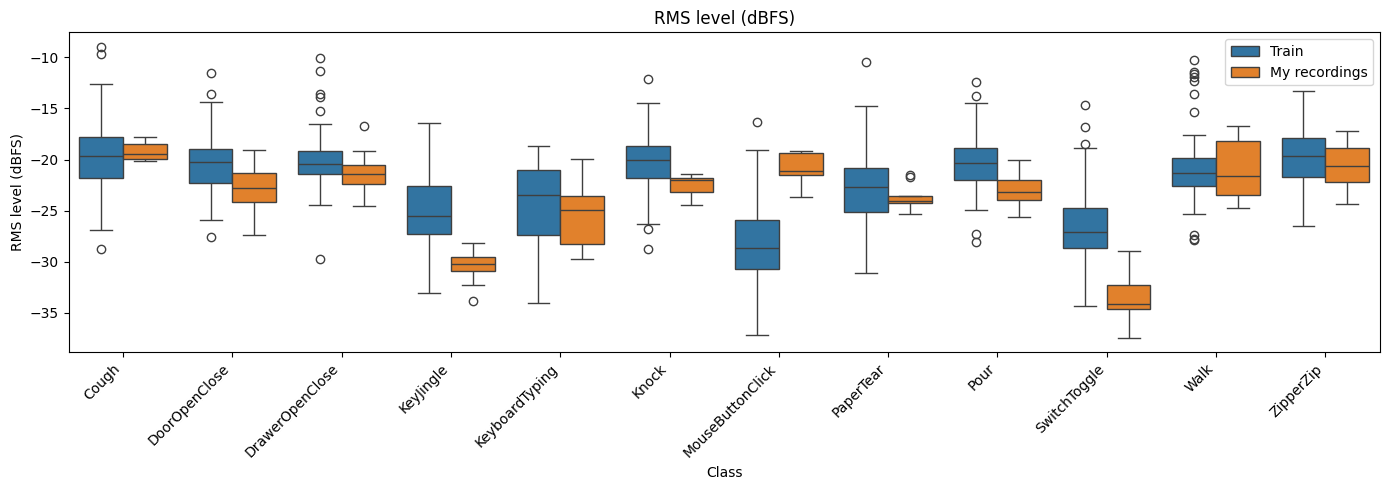

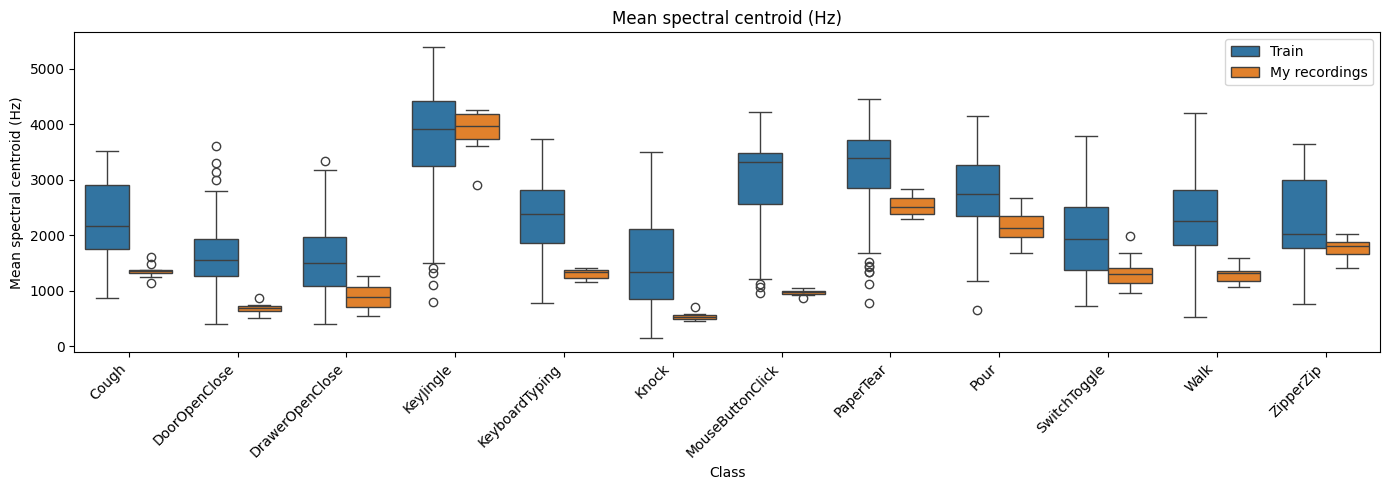

In [33]:
features = {
    "background_noise_dbfs": "Estimated background noise (dBFS)",
    "rms_dbfs": "RMS level (dBFS)",
    "spectral_centroid_mean": "Mean spectral centroid (Hz)",
}

for feature, title in features.items():
    plt.figure(figsize=(14, 5))

    sns.boxplot(
        x=train_df["label"].tolist() + y_my.tolist(),
        y=train_df[feature].tolist() + X_my[feature].tolist(),
        hue=["Train"] * len(train_df) + ["My recordings"] * len(X_my),
        order=class_names,
        dodge=True,
    )

    plt.title(title)
    plt.xlabel("Class")
    plt.ylabel(title)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

Estimated background noise varies less in most classes in my recordings than in the training set. The median noise level has both lower and higher levels, depending on the class.

Median RMS levels are lower for most classes in my recordings, with a clear decrease for `SwitchToggle` and `KeyJingle`. `MouseButtonClick` is the biggest exception, with a much higher median RMS level.

The most noticeable difference is that the median spectral centroid is lower in my recordings for almost every class except `KeyJingle`. The largest drop is for `MouseButtonClick`.